# Does silencing one residual branch change ResNet-18's predictions?

| | |
| --- | --- |
| **Question** | If the learned branch of one residual block in a pretrained ResNet-18 is silenced, do the network's top predictions change, and does the block itself keep passing activity through its shortcut? |
| **Requires** | CPU only. ResNet-18 ImageNet weights (about 45 MB, downloaded by torchvision on first use). Two photographs bundled with scikit-learn. About 10 seconds once the weights are cached. |
| **Lessons used** | [1. Your first subject](../lessons/01_your_first_subject.ipynb), [5. Layers and regions](../lessons/05_layers_and_regions.ipynb), [7. Perturb a model](../lessons/07_perturb_a_model.ipynb), [10. Run an experiment](../lessons/10_run_an_experiment.ipynb) |

## Background

A residual block adds a learned update (the branch) to an unchanged copy of its input (the shortcut). If the branch is silenced, the block still passes its input forward, so a residual network might tolerate the loss of one branch better than a plain feed-forward network tolerates the loss of a layer.

Measuring this requires recording two things at once: the network's predictions, and the activity inside the block, to confirm that the branch was silenced while the block output stayed active.

## Hypothesis

Silencing the branch of the first block in ResNet-18's third stage (`layer3.0`) will change the top prediction for both photographs. The branch output will be exactly zero, and the block output will stay nonzero because of the shortcut.

## Method

The model is ResNet-18 with its ImageNet weights, in evaluation mode. The inputs are two photographs, preprocessed with the transform that ships with the weights (resize, center crop and normalize). Three conditions receive identical inputs: intact, branch silenced, and restored after the lesion is removed.

The branch of `layer3.0` ends in the batch-normalization layer `layer3.0.bn2`. Silencing that layer zeroes the learned update and leaves the shortcut intact. Lesson 5 explains layer paths.

## Setup

Imports and settings.

In [1]:
# Keep the output short: no progress bars, no library warnings.
import warnings
from functools import partialmethod
from tqdm.auto import tqdm
import tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
warnings.filterwarnings('ignore')
import os
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # every requirement is already installed

from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.datasets import load_sample_images
from torchvision.models import resnet18, ResNet18_Weights


# ResNet-18 with its ImageNet weights, the matching preprocessing, and the 1,000 class names.
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).cpu().eval()
preprocess = weights.transforms()
class_names = weights.meta['categories']

## The subject

The network is wrapped as a subject that receives images on the `vision:image` channel and returns ImageNet class probabilities on the `behavior` channel. Lesson 1 explains this pattern.

In [2]:
from brainscore_core.model_interface import Subject
from brainscore_core.streaming import StreamEvent
from brainscore_core.supported_data_standards.brainio.assemblies import BehavioralAssembly

class ImageSubject(Subject):
    identifier = 'resnet18'
    in_channels = {'vision:image'}
    out_channels = {'behavior'}

    def __init__(self, model):
        self.model = model

    def participate(self, session):
        event = session.next_input()
        while event is not None:                # answer every input until the session ends
            with torch.inference_mode():
                pixels = torch.stack([preprocess(Image.fromarray(photo)) for photo in event.payload])
                probabilities = self.model(pixels).softmax(dim=1).numpy()
            responses = BehavioralAssembly(
                probabilities,
                dims=['presentation', 'choice'],
                coords={
                    'stimulus_id': ('presentation', np.arange(len(probabilities))),
                    'stimulus_index': ('presentation', np.arange(len(probabilities))),
                    'choice': ('choice', np.arange(probabilities.shape[1])),
                },
            )
            session.respond(StreamEvent(channel='behavior', payload=responses, t_ms=event.t_ms))
            event = session.next_input()

subject = ImageSubject(model)

## The experiment

### Stimuli

Two photographs bundled with scikit-learn. The figure shows the originals; the model receives their preprocessed center crops.

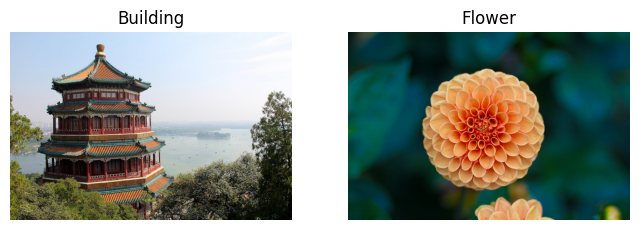

In [3]:
photos = load_sample_images().images
images = torch.stack([preprocess(Image.fromarray(photo)) for photo in photos])    # (2, 3, 224, 224)
PHOTO_NAMES = ['Building', 'Flower']

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, photo, name in zip(axes, photos, PHOTO_NAMES):
    ax.imshow(photo)
    ax.set_title(name)
    ax.axis('off')
plt.show()

### Task

Each condition is one session that presents both images at once and asks for the class probabilities. Each session receives an independent copy of the images. Lesson 10 explains protocols and tools.

In [4]:
from brainscore_core.streaming import Session
from brainscore.experiments import SessionProtocol

CONDITIONS = ['intact', 'silenced', 'restored']


@contextmanager
def make_session(trial):
    yield Session(
        [StreamEvent(channel='vision:image', payload=np.stack(photos), t_ms=0)],
        outputs=['behavior'],
    )


protocol = SessionProtocol(
    identifier='two-photos',
    session_factory=make_session,
    conditions=CONDITIONS,
    input_channels=['vision:image'],
    output_channels=['behavior'],
)

### Conditions

`Ablate` silences the branch in the `silenced` condition only. The `restored` condition runs after the lesion has been removed.

In [5]:
from brainscore.experiments import Ablate

lesion = Ablate(['layer3.0.bn2'], conditions=['silenced'])

## Run

`RecordInputsOutputs` keeps every input and answer. `RecordActivity` records the branch and the whole block; it comes after the lesion in the list of tools, so it records after the lesion is applied.

In [6]:
from brainscore.experiments import Experiment, RecordInputsOutputs, RecordActivity, TorchInstrumentation

experiment = Experiment(
    subject=subject,
    protocol=protocol,
    tools=[
        RecordInputsOutputs(),
        lesion,
        RecordActivity(['layer3.0.bn2', 'layer3.0']),
    ],
    instrumentation=TorchInstrumentation(model),
    metadata={'weights': str(weights), 'device': 'cpu'},
)
result = experiment.run()
print('Run status:', result.manifest['status'])

Run status: complete


## Read results back

The predictions and activity are read back from the saved record; this does not call the model again. Each prediction is a (photographs, classes) array of probabilities; each activity recording is the layer's output for both photographs.

In [7]:
predictions, activity = {}, {}
for event in result.record.events():
    if event['kind'] == 'output':
        predictions[event['condition']] = np.asarray(event['payload'].payload)
    elif event['kind'] == 'activity':
        activity[event['condition'], event['payload']['target']] = \
            event['payload']['value']['array']

print({condition: values.shape for condition, values in predictions.items()})
print({key: value.shape for key, value in activity.items()})

{'intact': (2, 1000), 'silenced': (2, 1000), 'restored': (2, 1000)}
{('intact', 'layer3.0.bn2'): (2, 256, 14, 14), ('intact', 'layer3.0'): (2, 256, 14, 14), ('silenced', 'layer3.0.bn2'): (2, 256, 14, 14), ('silenced', 'layer3.0'): (2, 256, 14, 14), ('restored', 'layer3.0.bn2'): (2, 256, 14, 14), ('restored', 'layer3.0'): (2, 256, 14, 14)}


## Analysis

In [8]:
def top_predictions(condition):
    """The top class and its probability for each photograph."""
    rows = []
    for name, values in zip(PHOTO_NAMES, predictions[condition]):
        best = values.argmax()
        rows.append({'photo': name, 'condition': condition,
                     'top prediction': class_names[best],
                     'probability (%)': round(float(values[best]) * 100, 1)})
    return rows

def mean_activity(condition, target):
    """Mean absolute activity, over both images, channels and spatial positions."""
    return np.abs(activity[condition, target]).mean()

## Results

The top class and its probability for each photograph and condition. These are predictions, not correctness scores; the intact model can be wrong.

In [9]:
pd.DataFrame([row for condition in CONDITIONS for row in top_predictions(condition)])

,photo,condition,top prediction,probability (%)
0,Building,intact,bell cote,53.6
1,Flower,intact,honeycomb,66.3
2,Building,silenced,laptop,59.0
3,Flower,silenced,laptop,14.0
4,Building,restored,bell cote,53.6
5,Flower,restored,honeycomb,66.3


Mean absolute activity of the branch and of the whole block. Each panel has its own scale.

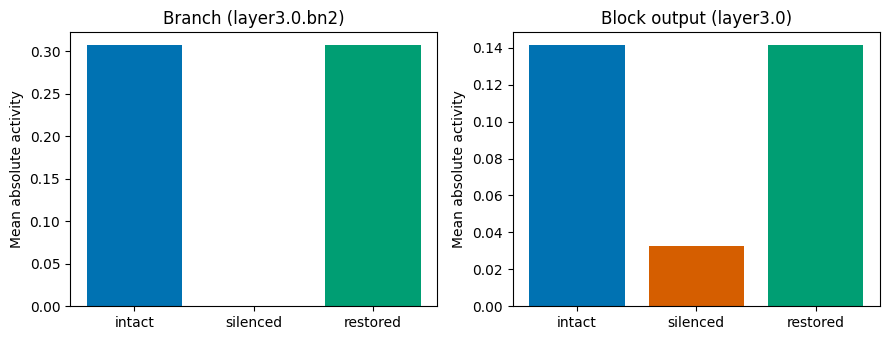

In [10]:
colors = ['#0072B2', '#D55E00', '#009E73']
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, target, title in zip(axes, ['layer3.0.bn2', 'layer3.0'],
                             ['Branch (layer3.0.bn2)', 'Block output (layer3.0)']):
    values = [mean_activity(condition, target) for condition in CONDITIONS]
    ax.bar(CONDITIONS, values, color=colors)
    ax.set_title(title)
    ax.set_ylabel('Mean absolute activity')
fig.tight_layout()
plt.show()

The checks the hypothesis needs: the branch is exactly zero when silenced, the block is not, the restored predictions equal the intact ones, and no hooks are left on the network.

In [11]:
assert np.count_nonzero(activity['silenced', 'layer3.0.bn2']) == 0
assert np.count_nonzero(activity['silenced', 'layer3.0']) > 0
np.testing.assert_array_equal(predictions['intact'], predictions['restored'])
for module in [model.layer3[0].bn2, model.layer3[0]]:
    assert not module._forward_hooks
print('Branch silenced, block output nonzero, restored predictions equal intact ones, hooks removed.')

Branch silenced, block output nonzero, restored predictions equal intact ones, hooks removed.


With the branch silenced, the top prediction changes for both photographs (bell cote to laptop, and honeycomb to laptop). The branch output is exactly zero in the silenced condition, while the block output remains nonzero. The restored condition reproduces the intact probabilities exactly.

## Conclusion and limits

Silencing one residual branch was enough to change the top prediction for both photographs, even though the block kept passing activity through its shortcut. The restored condition reproduced the intact predictions exactly, so the change was caused by the lesion.

Two photographs are far too few to estimate how much accuracy the lesion costs, and the intact model already misclassifies one of them. The experiment does not say what the branch represents, and it makes no claim about the brain. A real study would use a labeled image set, several blocks, and a size-matched control such as silencing random channels (see [8. Choose units](../lessons/08_choose_units.ipynb)). To repeat the run from its saved inputs, see the replay section of Lesson 10.

**Photo credits:** scikit-learn's `china.jpg` by [danielbuechele](https://www.flickr.com/photos/danielbuechele/6061409035/) and `flower.jpg` by [vultilion](https://www.flickr.com/photos/vultilion/6056698931/), distributed under [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/). Model weights: [torchvision ResNet-18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).

Back to the [notebook index](../README.md) and the [documentation](../../docs/README.md).